In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Mateix directori arrel que als teus notebooks
ROOT_DIR = Path.cwd().resolve().parents[1]
carpeta_dades = ROOT_DIR / "data" / "processed" / "education"

ruta_global = carpeta_dades / "resultats_academics__quart_eso_processat.csv"
ruta_pub100k = carpeta_dades / "resultats_academics_quart_eso_processat_nou.csv"

cols_notes = ["PCAT", "PCAT_CL", "PCAT_EE", "PMAT"]

# ---------------------------------------------------------
# 1. Processament de l'arxiu GLOBAL (tots els centres)
# ---------------------------------------------------------
df_global = pd.read_csv(ruta_global, sep=";", decimal=",")

df_global["GENERE"] = df_global["GENERE"].astype(str).str.strip().str.upper()
df_global = df_global[df_global["GENERE"].isin(["H", "D"])].copy()

df_global["ANY"] = pd.to_numeric(df_global["ANY"], errors="coerce")
for col in cols_notes:
    df_global[col] = pd.to_numeric(
        df_global[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

df_global_net = (
    df_global
    .dropna(subset=["ANY"])
    .dropna(subset=cols_notes, how="all")
    .copy()
)
df_global_net["ANY"] = df_global_net["ANY"].astype(int)

mitjanes_global = (
    df_global_net
    .groupby("ANY")[cols_notes]
    .mean()
    .sort_index()
)

# ---------------------------------------------------------
# 2. Processament de l'arxiu PÚBLIQUES (<= 100k habitants)
# ---------------------------------------------------------
df_pub = pd.read_csv(ruta_pub100k, sep=";", encoding="utf-8", encoding_errors="replace")
if df_pub.shape[1] == 1:
    df_pub = pd.read_csv(ruta_pub100k, sep=",", encoding="utf-8", encoding_errors="replace")

df_pub_net = pd.DataFrame({
    "ANY": pd.to_numeric(df_pub.iloc[:, 0], errors="coerce"),
    "PCAT": pd.to_numeric(df_pub.iloc[:, 1].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "PCAT_CL": pd.to_numeric(df_pub.iloc[:, 2].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "PCAT_EE": pd.to_numeric(df_pub.iloc[:, 3].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "PMAT": pd.to_numeric(df_pub.iloc[:, 4].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "NATURALESA": df_pub.iloc[:, 5].astype(str).str.strip(),
    "HABITAT": df_pub.iloc[:, 7].astype(str).str.strip()
})

cond_publica = (
    (~df_pub_net["NATURALESA"].str.contains("privada", case=False, na=False))
    & (df_pub_net["NATURALESA"] != "")
    & (df_pub_net["NATURALESA"].str.lower() != "nan")
)
cond_habitat = df_pub_net["HABITAT"].isin(["Fins a 10000", "De 10001 a 100000"])

df_pub_filtrat = (
    df_pub_net[cond_publica & cond_habitat]
    .dropna(subset=["ANY"])
    .dropna(subset=cols_notes, how="all")
    .copy()
)
df_pub_filtrat["ANY"] = df_pub_filtrat["ANY"].astype(int)

mitjanes_pub100k = (
    df_pub_filtrat
    .groupby("ANY")[cols_notes]
    .mean()
    .sort_index()
)

print(f"Alumnes vàlids (Global): {len(df_global_net)}")
print(f"Alumnes vàlids (Públiques ≤ 100k): {len(df_pub_filtrat)}")

C:\Users\carle\AppData\Local\Temp\ipykernel_17028\3342000485.py:47: DtypeWarning: Columns (2: PCAT_CL) have mixed types. Specify dtype option on import or set low_memory=False.
  df_pub = pd.read_csv(ruta_pub100k, sep=";", encoding="utf-8", encoding_errors="replace")


Alumnes vàlids (Global): 914591
Alumnes vàlids (Públiques ≤ 100k): 409549


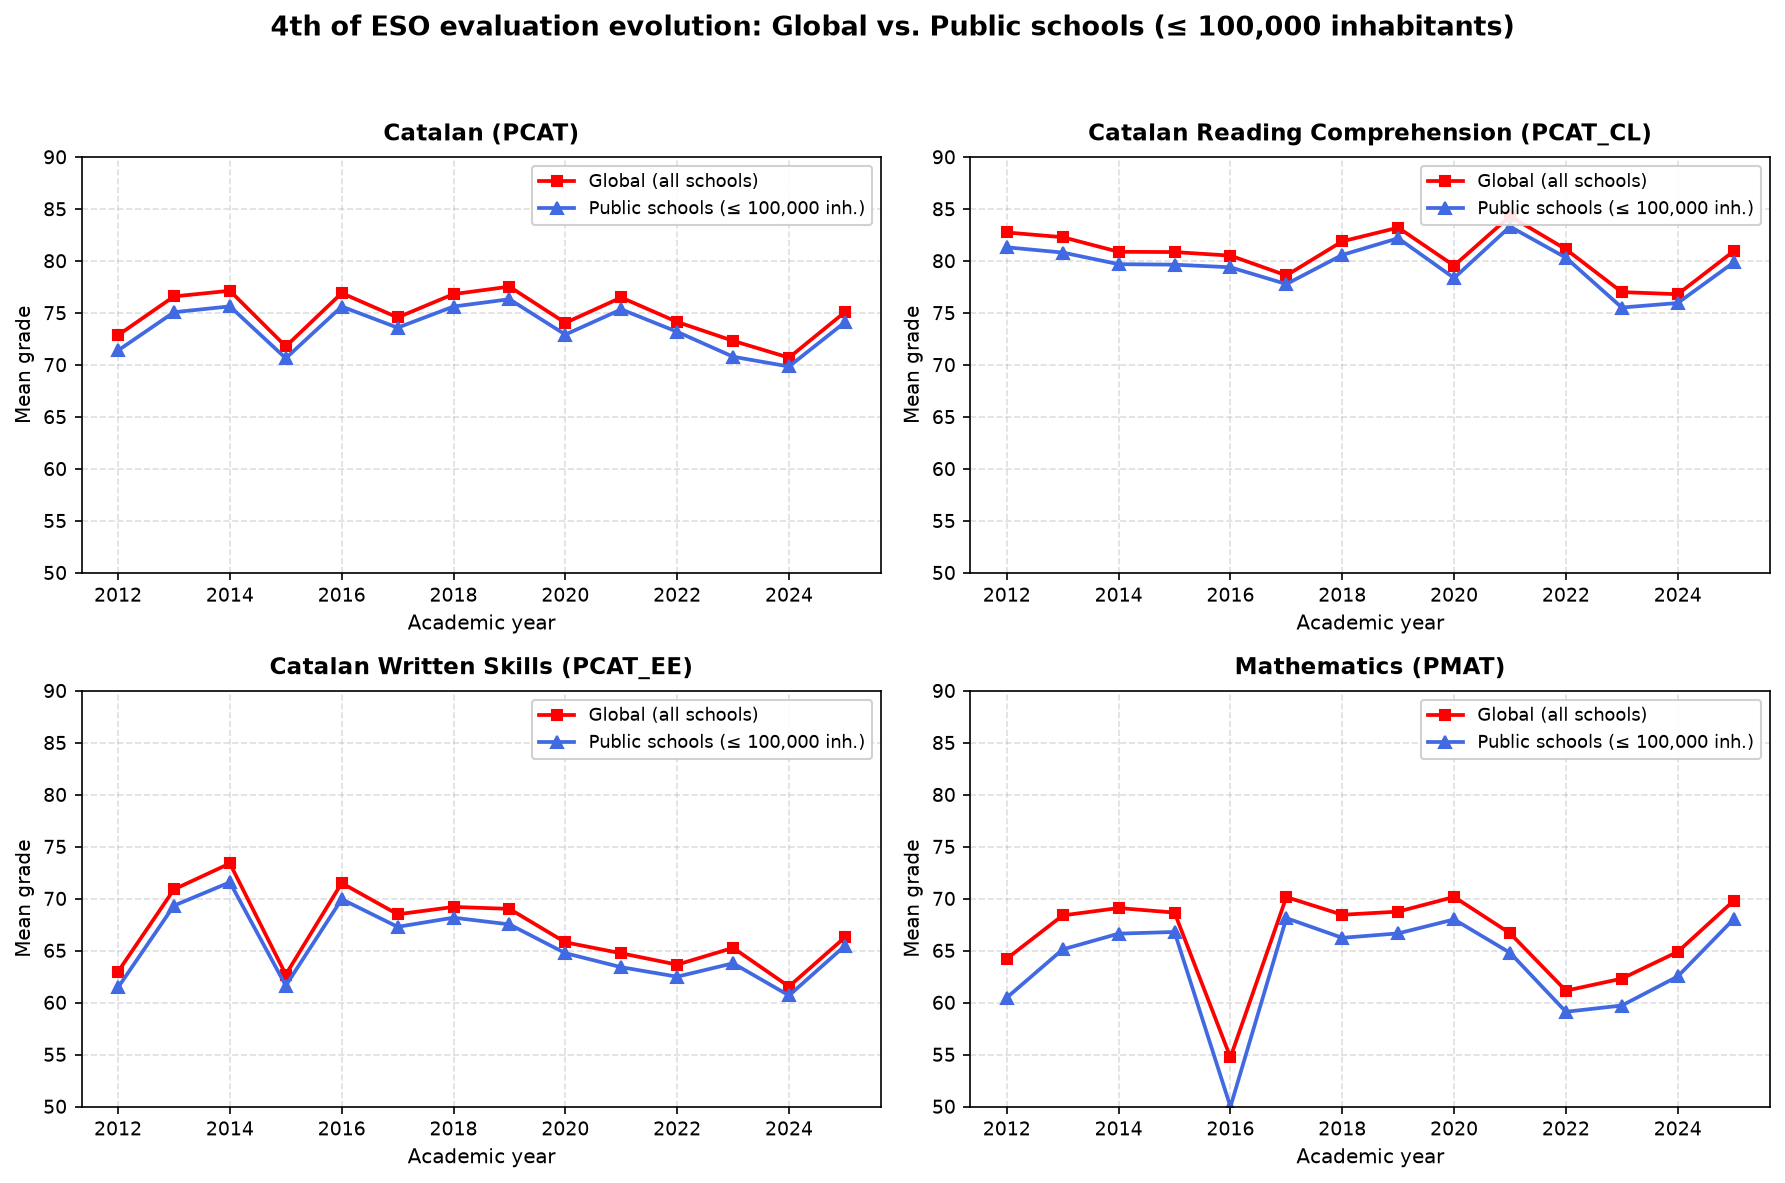

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=150)

competencies = [
    ("PCAT", "Catalan (PCAT)", axes[0, 0]),
    ("PCAT_CL", "Catalan Reading Comprehension (PCAT_CL)", axes[0, 1]),
    ("PCAT_EE", "Catalan Written Skills (PCAT_EE)", axes[1, 0]),
    ("PMAT", "Mathematics (PMAT)", axes[1, 1])
]

for col, titol, ax in competencies:
    # 1. Global: quadradets vermells
    ax.plot(
        mitjanes_global.index,
        mitjanes_global[col],
        color="red",
        marker="s",
        markersize=5,
        linewidth=1.8,
        label="Global (all schools)"
    )
    
    # 2. Públiques <= 100.000 habitants: trianglets blaus
    ax.plot(
        mitjanes_pub100k.index,
        mitjanes_pub100k[col],
        color="royalblue",
        marker="^",
        markersize=6,
        linewidth=1.8,
        label="Public schools (≤ 100,000 inh.)"
    )
    
    ax.set_title(titol, fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Academic year", fontsize=9.5)
    ax.set_ylabel("Mean grade", fontsize=9.5)
    ax.set_ylim(50, 90)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.tick_params(axis="both", labelsize=9)
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

fig.suptitle(
    "4th of ESO evaluation evolution: Global vs. Public schools (≤ 100,000 inhabitants)",
    fontsize=13,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Desem la figura comparativa a la carpeta de resultats
ruta_figura = ROOT_DIR / "results" / "figures" / "evolucio_4t_eso_comparativa.png"
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")

plt.show()